# 8.5 Parameter-Efficient Fine-Tuning (PEFT)

**Module 8 · Note 5**

In Note 8.4 we fine-tuned every one of DistilBERT's 66,955,010 weights. It worked, but it was expensive in ways that grow painfully with model size. Training needed memory for every weight's gradient and optimiser state. The result was a complete copy of the model, hundreds of megabytes, for one task. And the model lost some of its original skill along the way. For a model with billions of parameters, full fine-tuning needs a large GPU cluster, and every task needs its own multi-gigabyte copy.

**Parameter-efficient fine-tuning (PEFT)** asks: what if we leave the pretrained weights exactly as they are, and train only a small number of extra ones? This note builds up to the most widely used PEFT method, **LoRA** (low-rank adaptation). We start from what makes full fine-tuning expensive, measure evidence that the changes fine-tuning makes have a simple structure, build a LoRA layer by hand, then use Hugging Face's PEFT library to fine-tune DistilBERT on the same 1,000 reviews as Note 8.4, and compare the two on the same test reviews.

**Key question:** *Can we adapt a model just as well while training only a tiny fraction of its parameters?*

**By the end of this note you will be able to:**
- account for the memory full fine-tuning needs: weights, gradients and optimiser states;
- freeze parameters and explain what that saves;
- explain the core idea of PEFT, and the evidence that fine-tuning updates are approximately low-rank;
- build a LoRA layer and explain rank, alpha and the choice of target layers;
- fine-tune with LoRA using Hugging Face PEFT, and inspect, save, reload and merge the result;
- compare LoRA with full fine-tuning on accuracy, cost and forgetting.

**Before you start:** read Note 8.4; this note follows the same recipe and compares against its saved results. You'll also use matrix multiplication and shapes (Module 2), AdamW (Note 8.4), and the forgetting measure (Note 8.1).

### Setup

The usual imports, seeds and device check, and the same harmless warnings as before, including the LoRA-related messages that the PEFT library prints. Training takes under a minute on a fast laptop CPU (Section 8).

In [1]:
import os, json, time, copy, math, shutil, hashlib
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from datasets import load_dataset
from huggingface_hub import get_safetensors_metadata
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoModelForMaskedLM,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)
from peft import LoraConfig, get_peft_model, PeftModel

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1017 20:22:44.600000 99824 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 20:22:44.687000 99824 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 20:22:44.707000 99824 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PyTorch 2.14.1 | device: cpu


## 1. The Big Picture: Adapting a Model While Training Fewer Parameters

Full fine-tuning changes every weight W of the pretrained model to W + ΔW, where ΔW (delta W) is whatever training adds. PEFT keeps W **frozen** and learns only a compact replacement for ΔW, or a few small extra pieces of network. The pretrained model is then shared: one copy of the large weights, plus a small, swappable piece for each task.

The rest of this note answers four questions:
1. Why is full fine-tuning so expensive? (Section 2)
2. Why can a small number of trained parameters be enough? (Sections 3–4)
3. How does LoRA work, and what are its settings? (Sections 5–7)
4. Does it work as well, here? (Sections 8–9)

> 🖼 *IMAGE 8.5.1 — Full Fine-Tuning vs. LoRA.* Two side-by-side panels on a white background. Left, "Full fine-tuning": a large blue square labelled "W (768 × 768)" turning entirely orange, labelled "every weight updated → a full copy per task". Right, "LoRA": the same blue square with a padlock, labelled "W frozen", and beside it a plus sign followed by two thin orange rectangles, a tall narrow one "B (768 × 8)" and a short wide one "A (8 × 768)", multiplied together and labelled "ΔW = B·A, rank 8: 12,288 trainable numbers instead of 589,824". Under the right panel, a row of three small orange strips labelled "task 1", "task 2", "task 3" attached to one shared blue model. Colours: blue = pretrained weights, orange = trained weights, padlock = frozen. Takeaway: LoRA freezes the big matrix and learns a thin, low-rank correction beside it.

### The data

The same fixed split, the same 1,000 training reviews (checked by fingerprint), head+tail truncation to 128 tokens, and the same helpers as Note 8.4. We load the starting model once and copy it for each experiment below.

In [2]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"})
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [3]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")
train_x, train_y = imdb["train"][0][:1000], imdb["train"][1][:1000]     # the 1,000 labelled reviews of Module 8
val_x, val_y = imdb["val_eval"]
test_x, test_y = imdb["test_eval"]
print("Module 8 training set fingerprint:", fingerprint(train_x))

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc
Module 8 training set fingerprint: 7b0ca50110ca


In [4]:
BASE = "distilbert/distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(BASE)

def head_tail_ids(texts, max_length=128):
    """Token IDs keeping the first quarter and last three quarters of the budget (built in Note 8.2)."""
    keep = max_length - 2
    out = []
    for ids in tok(texts, add_special_tokens=False)["input_ids"]:
        if len(ids) > keep:
            ids = ids[:keep // 4] + ids[-(keep - keep // 4):]
        out.append([tok.cls_token_id] + ids + [tok.sep_token_id])
    return out

collate = DataCollatorWithPadding(tok)
def make_batch(ids_list, labels=None):
    rows = [{"input_ids": ids} for ids in ids_list] if labels is None else \
           [{"input_ids": ids, "labels": int(y)} for ids, y in zip(ids_list, labels)]
    return {k: v.to(device) for k, v in collate(rows).items()}

def predict(m, ids_list, batch_size=64):
    m.eval()
    order = np.argsort([len(x) for x in ids_list])
    probs = np.empty(len(ids_list))
    with torch.inference_mode():
        for i in range(0, len(ids_list), batch_size):
            idx = order[i:i + batch_size]
            probs[idx] = m(**make_batch([ids_list[j] for j in idx])).logits.softmax(-1)[:, 1].cpu().numpy()
    return probs

train_ids, val_ids, test_ids = head_tail_ids(train_x), head_tail_ids(val_x), head_tail_ids(test_x)
LABELS = dict(num_labels=2, id2label={0: "NEGATIVE", 1: "POSITIVE"}, label2id={"NEGATIVE": 0, "POSITIVE": 1})
torch.manual_seed(0)
start = AutoModelForSequenceClassification.from_pretrained(BASE, **LABELS)   # loaded once; copied for each experiment

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (544 > 512). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 22665.79it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 2. Why Full Fine-Tuning Is Expensive: Weights, Gradients and Optimizer States

During training, memory is needed for more than the weights. Every trainable weight also needs a **gradient** of the same size, and the AdamW optimiser keeps two **optimiser states** per weight: a running average of the gradients and a running average of their squares. Let's measure all three after one full fine-tuning step on DistilBERT:

In [5]:
full = copy.deepcopy(start).to(device)
opt = torch.optim.AdamW(full.parameters(), lr=5e-5)
full.train()
full(**make_batch(train_ids[:16], train_y[:16])).loss.backward()
opt.step()
mb = lambda tensors: sum(t.numel() * t.element_size() for t in tensors) / 1e6
weights = mb(full.parameters())
grads = mb(p.grad for p in full.parameters())
adam = mb(v for state in opt.state.values() for v in state.values() if torch.is_tensor(v) and v.dim() > 0)
print(f"full fine-tuning of DistilBERT, float32: weights {weights:.1f} MB | gradients {grads:.1f} MB | "
      f"Adam states {adam:.1f} MB | total {weights + grads + adam:.1f} MB (before activations)")
del full, opt

full fine-tuning of DistilBERT, float32: weights 267.8 MB | gradients 267.8 MB | Adam states 535.6 MB | total 1071.3 MB (before activations)


In float32 the weights take 267.8 MB, the gradients another 267.8 MB, and Adam's states 535.6 MB, twice as much. That is 1071.3 MB in total, four times the model's size, before counting the activations a batch needs. The rule of thumb: full fine-tuning with Adam needs about **16 bytes per parameter** in float32 (4 for the weight, 4 for its gradient, 8 for the two states).

For a small model that's manageable. For a modern large model it's not:

In [6]:
n7b = sum(get_safetensors_metadata("Qwen/Qwen2.5-7B").parameter_count.values())   # header only (Note 7.3)
print(f"a 7B model: {n7b:,} parameters")
for label, per_param in [("weights only (inference, bfloat16)", 2),
                         ("full fine-tuning, float32: weights + gradients + 2 Adam states", 4 * 4)]:
    print(f"  {label:<62} {n7b * per_param / 1e9:7.1f} GB")

Parse safetensors files:   0%|          | 0/4 [00:00<?, ?it/s]

Parse safetensors files:  25%|██▌       | 1/4 [00:02<00:08,  2.68s/it]

Parse safetensors files:  75%|███████▌  | 3/4 [00:03<00:00,  1.14it/s]

Parse safetensors files: 100%|██████████| 4/4 [00:03<00:00,  1.63it/s]

Parse safetensors files: 100%|██████████| 4/4 [00:03<00:00,  1.22it/s]

a 7B model: 7,615,616,512 parameters
  weights only (inference, bfloat16)                                15.2 GB
  full fine-tuning, float32: weights + gradients + 2 Adam states   121.8 GB


A 7-billion-parameter model (here Qwen2.5-7B, counted from its file header as in Note 7.3) needs 15.2 GB just to run in bfloat16. Fully fine-tuning it in float32 needs about 121.8 GB for weights, gradients and Adam states, far beyond any single consumer GPU. (Mixed-precision training reduces this somewhat, but not by enough to change the conclusion.) And each fine-tuned copy must be stored and served separately.

> **Key terms**
> - **Optimiser state:** extra numbers an optimiser keeps for each trainable weight; AdamW keeps two (running averages of the gradient and of its square).
> - **Training memory:** weights + gradients + optimiser states + activations; about 16 bytes per trainable parameter in float32 with Adam, before activations.

> **Check yourself 1.** If only 1% of a model's parameters are trainable, which parts of the training memory shrink, and which don't?

## 3. Frozen vs. Trainable Parameters

The simplest way to save memory is to **freeze** parameters: set `requires_grad = False`, so PyTorch computes no gradient for them and the optimiser keeps no state for them. Here we freeze DistilBERT's whole body and train only the head, the "head only" end of the spectrum:

In [7]:
m = copy.deepcopy(start).to(device)
for name, p in m.named_parameters():
    p.requires_grad = not name.startswith("distilbert.")              # freeze the body, train only the head
m.train()
m(**make_batch(train_ids[:16], train_y[:16])).loss.backward()
trainable = [(n, p) for n, p in m.named_parameters() if p.requires_grad]
print(f"trainable: {sum(p.numel() for _, p in trainable):,} of {sum(p.numel() for p in m.parameters()):,}")
print("a frozen weight's gradient:", m.distilbert.transformer.layer[0].attention.q_lin.weight.grad)
print("a trainable weight's gradient shape:", tuple(m.classifier.weight.grad.shape))
del m

trainable: 592,130 of 66,955,010
a frozen weight's gradient: None
a trainable weight's gradient shape: (2, 768)


Only 592,130 of the 66,955,010 parameters are trainable now. After a backward pass, a frozen weight's gradient is `None`: none was computed, and none is stored. The head's gradient exists, with the shape of the head's weights. Frozen parameters still take memory as weights, and still take part in the forward pass, but they need no gradients and no optimiser state.

Freezing the whole body is very cheap, but it's close to feature extraction (Note 8.3), and the body can't adapt at all. PEFT methods keep the body frozen but add a *small* number of trainable parameters *inside* it, so the representation itself can adapt.

> **Key terms**
> - **`requires_grad`:** the flag that decides whether PyTorch computes a gradient for a tensor; `False` freezes it.
> - **Trainable parameters:** those with `requires_grad = True`; only these get gradients and optimiser states.

## 4. The Core Idea Behind PEFT

Why should a small number of extra parameters be enough to adapt a model? Because the *change* that fine-tuning makes seems to be much simpler than the weights themselves.

We can check this with a model we already have. The SST-2 sentiment model is DistilBERT base after full fine-tuning (Note 7.1). For one weight matrix, the attention query projection, we take the update ΔW = W(SST-2) − W(base) and ask how many "directions" it really uses. The **singular value decomposition** splits any matrix into a sum of simple rank-1 pieces, each a direction with a strength, sorted from strongest to weakest. If a few pieces carry most of the update, the update is approximately **low-rank**.

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 18198.06it/s]

layer 0: the top 8 of 768 directions hold 25.1% of the update | top 64 hold 60.6%
layer 5: the top 8 of 768 directions hold 55.8% of the update | top 64 hold 85.1%
random 768 x 768 matrix: the top 8 directions hold 4.0%


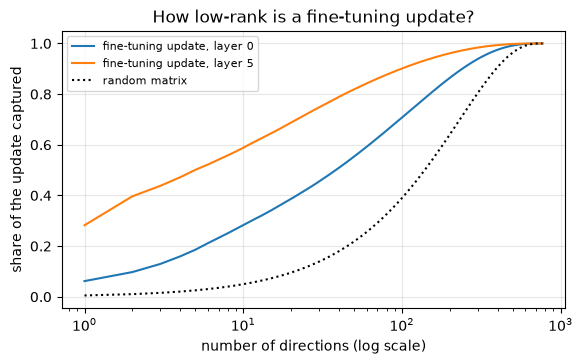

In [8]:
sst2 = AutoModelForSequenceClassification.from_pretrained("distilbert/distilbert-base-uncased-finetuned-sst-2-english")
base_body = start.distilbert
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for layer in (0, 5):
    W0 = base_body.transformer.layer[layer].attention.q_lin.weight.detach()
    W1 = sst2.distilbert.transformer.layer[layer].attention.q_lin.weight.detach()
    s = torch.linalg.svdvals(W1 - W0)                                 # singular values of the fine-tuning update
    energy = (s ** 2).cumsum(0) / (s ** 2).sum()
    print(f"layer {layer}: the top 8 of {len(s)} directions hold {energy[7]:.1%} of the update | top 64 hold {energy[63]:.1%}")
    ax.plot(range(1, len(s) + 1), energy.numpy(), label=f"fine-tuning update, layer {layer}")
R = torch.randn(768, 768)
er = (torch.linalg.svdvals(R) ** 2).cumsum(0) / (torch.linalg.svdvals(R) ** 2).sum()
print(f"random 768 x 768 matrix: the top 8 directions hold {er[7]:.1%}")
ax.plot(range(1, 769), er.numpy(), "k:", label="random matrix")
ax.set_xscale("log"); ax.set_xlabel("number of directions (log scale)"); ax.set_ylabel("share of the update captured")
ax.set_title("How low-rank is a fine-tuning update?"); ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
del sst2

The fine-tuning updates are strongly concentrated. In the last layer, just 8 of the 768 directions carry 55.8% of the update, and 64 directions carry 85.1%. In the first layer the update is more spread out (25.1% in the top 8), but still far more concentrated than a random matrix of the same size, whose top 8 directions hold only 4.0%. The plot shows the whole curve: the fine-tuning updates rise steeply on the left, while the random matrix needs hundreds of directions.

That's the core idea behind LoRA. If ΔW is approximately low-rank, we can *learn it directly in low-rank form*, with far fewer numbers than a full matrix, and leave W untouched.

> **Key terms**
> - **Rank:** the number of independent directions a matrix uses; a 768 × 768 matrix can have rank up to 768.
> - **Low-rank:** representable (exactly or approximately) with few directions.
> - **Singular value decomposition (SVD):** splitting a matrix into rank-1 pieces ordered by strength; used here to measure how low-rank an update is.

> **Check yourself 2.** The last layer's update is more concentrated (55.8% in 8 directions) than the first layer's (25.1%). Suggest one reason why fine-tuning might change the last layer in a simpler, more focused way.

## 5. LoRA: The Intuition

A rank-r matrix of size 768 × 768 can always be written as the product of a tall, thin matrix **B** (768 × r) and a short, wide matrix **A** (r × 768). For r = 8 that's 2 × 8 × 768 = 12,288 numbers instead of 589,824. LoRA uses exactly this: next to a frozen weight matrix W, it adds a trainable update in factorised form, so the layer computes

> output = W·x + (α / r) · B·(A·x)

where x is the input vector, r is the **rank**, and α (**alpha**) is a fixed scaling number.

Two design details make this work well:
- **B starts at zero.** So at the start of training B·A = 0, and the model behaves *exactly* like the pretrained model. Training only ever adds a learned correction.
- **A starts small and random,** so the gradients for B are non-zero from the first step and learning can begin.

An analogy: W is a large printed map that we're not allowed to redraw. LoRA is a transparent overlay on which we may draw only a few straight strokes (the rank). For many trips, a few strokes are enough to mark the new route.

## 6. LoRA Matrices and Low-Rank Updates: Rank, Alpha, Target Layers

### 6.1 A LoRA layer by hand

Here is a complete LoRA layer in a few lines, wrapping an ordinary `nn.Linear`:

In [9]:
class LoRALinear(nn.Module):
    """A frozen linear layer plus a trainable low-rank update: W x + (alpha / r) * B (A x)."""
    def __init__(self, base: nn.Linear, r=8, alpha=16):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False                                   # the pretrained weight stays frozen
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.01)   # (r, d_in): small random
        self.B = nn.Parameter(torch.zeros(base.out_features, r))          # (d_out, r): zero, so the update starts at 0
        self.scale = alpha / r
    def forward(self, x):                                             # x: (..., d_in)
        return self.base(x) + self.scale * (x @ self.A.T) @ self.B.T  # (..., d_out)

q = nn.Linear(768, 768)
lora_q = LoRALinear(q, r=8, alpha=16)
x = torch.randn(2, 5, 768)                                            # 2 sequences of 5 token vectors
print("output unchanged at the start:", torch.equal(q(x), lora_q(x)))
print(f"trainable in this layer: {sum(p.numel() for p in lora_q.parameters() if p.requires_grad):,} "
      f"instead of {q.weight.numel():,} ({8 * (768 + 768) / q.weight.numel():.1%})")

output unchanged at the start: True
trainable in this layer: 12,288 instead of 589,824 (2.1%)


At the start, the LoRA layer's output is exactly the same as the original layer's, because B is zero. The trainable part is 12,288 numbers instead of the matrix's 589,824, 2.1% of it.

### 6.2 Rank

The rank r sets the size of the update, and the trade-off between capacity and cost:

In [10]:
for r in (1, 4, 8, 16, 64, 384):
    per_matrix = r * (768 + 768)
    print(f"rank {r:>3}: {per_matrix:>7,} trainable numbers per 768 x 768 matrix ({per_matrix / 768 ** 2:6.1%} of it)")

rank   1:   1,536 trainable numbers per 768 x 768 matrix (  0.3% of it)
rank   4:   6,144 trainable numbers per 768 x 768 matrix (  1.0% of it)
rank   8:  12,288 trainable numbers per 768 x 768 matrix (  2.1% of it)
rank  16:  24,576 trainable numbers per 768 x 768 matrix (  4.2% of it)
rank  64:  98,304 trainable numbers per 768 x 768 matrix ( 16.7% of it)
rank 384: 589,824 trainable numbers per 768 x 768 matrix (100.0% of it)


Rank 1 needs only 1,536 numbers (0.3% of the matrix); rank 8, 12,288 (2.1%); rank 64, 98,304 (16.7%). At rank 384, half the matrix's width, LoRA already has as many numbers as the full matrix, and there's nothing left to save. In practice, ranks from 4 to 64 are common, and Section 4's measurements suggest why small ranks often suffice.

**Alpha** scales the update by α / r. Its purpose is practical: when you try a different rank, you can keep α fixed, and the update's overall size stays comparable, so you don't have to re-tune the learning rate. We use r = 8 and α = 16, so the scale is 2.

### 6.3 Target layers

Which matrices get a LoRA update? A Transformer layer (Note 6.4) has the attention projections (query, key, value and output; `q_lin`, `k_lin`, `v_lin` and `out_lin` in DistilBERT) and the feed-forward network (`lin1`, `lin2`). The PEFT library takes a list of names, `target_modules`, and counts follow directly:

In [11]:
for targets in (["q_lin", "v_lin"], ["q_lin", "k_lin", "v_lin", "out_lin"], ["q_lin", "k_lin", "v_lin", "out_lin", "lin1", "lin2"]):
    pm = get_peft_model(copy.deepcopy(start),
                        LoraConfig(r=8, lora_alpha=16, target_modules=targets, task_type="SEQ_CLS"))
    lora_n = sum(p.numel() for n, p in pm.named_parameters() if "lora_" in n)
    total = sum(p.numel() for p in pm.parameters() if p.requires_grad)
    print(f"LoRA on {', '.join(targets):<38} LoRA weights {lora_n:>9,} | all trainable (incl. head) {total:>9,}")
del pm

LoRA on q_lin, v_lin                           LoRA weights   147,456 | all trainable (incl. head)   739,586


LoRA on q_lin, k_lin, v_lin, out_lin           LoRA weights   294,912 | all trainable (incl. head)   887,042
LoRA on q_lin, k_lin, v_lin, out_lin, lin1, lin2 LoRA weights   663,552 | all trainable (incl. head) 1,255,682


LoRA on only the query and value projections adds 147,456 trainable numbers across DistilBERT's 6 layers; on all four attention projections, 294,912; on everything including the feed-forward layers, 663,552. In each case the new classification head (592,130 parameters) is also trained, because it starts random and has to be learned. The original LoRA work found query and value enough for many tasks, and that is our choice. Targeting more layers gives the update more capacity, at a modest cost.

> **Key terms**
> - **LoRA rank (r):** the inner dimension of the factorised update B·A; it sets how many directions the update can use.
> - **LoRA alpha (α):** a scaling constant; the update is multiplied by α / r.
> - **Target modules:** the weight matrices that receive LoRA updates.

> **Common mistake:** forgetting that the classification head must be trained too. LoRA adapts the frozen *body*, but a new task's head starts random. The PEFT library trains it automatically when `task_type="SEQ_CLS"` is set; in a hand-built setup you must make it trainable yourself, or the model can't learn the task at all.

## 7. Adapters, Prefix Tuning and Other Approaches *(Extension)*

LoRA is one member of a family. Two other well-known PEFT methods, for comparison:
- **Bottleneck adapters** insert small two-layer networks inside each Transformer layer: squeeze the 768-number vector down to a small size m, apply a non-linearity, and expand back, with a residual connection around them. The pretrained weights stay frozen.
- **Prefix tuning** (and its simpler relative, *prompt tuning*) leaves every weight untouched and instead learns a few extra vectors that are prepended to the keys and values in each attention layer: "virtual tokens" the real tokens can attend to.

We can compare their sizes for DistilBERT by counting:

In [12]:
d, layers, m_ = 768, 6, 64                                            # model width, layers, adapter bottleneck size
adapter = layers * 2 * (2 * d * m_ + m_ + d)                          # two bottleneck adapters per layer
prefix = layers * 2 * 20 * d                                          # 20 learned key and value vectors per layer
lora = layers * 2 * 8 * (d + d)                                       # LoRA r=8 on two 768 x 768 matrices per layer
print(f"bottleneck adapters (size {m_}): {adapter:,} | prefix tuning (20 vectors): {prefix:,} | LoRA r=8 on q, v: {lora:,}")

bottleneck adapters (size 64): 1,189,632 | prefix tuning (20 vectors): 184,320 | LoRA r=8 on q, v: 147,456


With a bottleneck size of 64, two adapters per layer add 1,189,632 parameters; prefix tuning with 20 vectors adds 184,320; LoRA with rank 8 on query and value adds 147,456. All three are around 1–2% of the model or less. They differ in other ways:
- **Adapters** add extra layers that run at inference time, which adds a little latency.
- **Prefix tuning** uses up some of the context length.
- **LoRA's update can be merged into W after training** (Section 9), so the final model has *no* extra cost at all.

That last property is a large part of why LoRA became the default choice.

> **Key terms**
> - **Bottleneck adapter:** a small down-projection, non-linearity and up-projection inserted into each layer, trained while the rest is frozen.
> - **Prefix tuning / prompt tuning:** learning extra key/value or input vectors while all weights stay frozen.

## 8. Practice: LoRA with Hugging Face PEFT, Inspecting Trainable Parameters

### 8.1 Setting up

The PEFT library wraps a model in a few lines: describe LoRA in a `LoraConfig`, then call `get_peft_model`. We use rank 8, alpha 16, LoRA dropout 0.1 (dropout applied to the LoRA input during training), and the query and value projections. `task_type="SEQ_CLS"` tells the library this is sequence classification, so it also makes the new head trainable.

The training recipe is Note 8.4's, unchanged except for the learning rate: 1e-3 instead of 5e-5. LoRA trains small new matrices that start at zero, not pretrained weights that must be preserved, so it needs larger steps. Rates around 1e-4 to 1e-3 are typical. We use a common default here rather than tuning it, which would mean another training run.

In [13]:
EPOCHS, BATCH, LR, WARMUP = 1, 16, 1e-3, 0.1
config = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.1, target_modules=["q_lin", "v_lin"], task_type="SEQ_CLS")
torch.manual_seed(0)
model = get_peft_model(copy.deepcopy(start), config).to(device)
model.print_trainable_parameters()
lora_n = sum(p.numel() for n, p in model.named_parameters() if p.requires_grad and "lora_" in n)
head_n = sum(p.numel() for n, p in model.named_parameters() if p.requires_grad and "lora_" not in n)
print(f"LoRA matrices: {lora_n:,} | new classification head: {head_n:,}")

trainable params: 739,586 || all params: 67,694,596 || trainable%: 1.0925
LoRA matrices: 147,456 | new classification head: 592,130


`print_trainable_parameters` reports 739,586 trainable out of 67,694,596, 1.0925%. Of these, 147,456 are the LoRA matrices and 592,130 are the new head. The total count is a little larger than DistilBERT's 66,955,010 because the wrapped model also contains the LoRA matrices and a spare copy of the original head, kept so the adapter can be removed again.

### 8.2 Training

The loop is identical to Note 8.4's, except that the optimiser only receives the trainable parameters, and clipping applies only to them. Checkpoints are checked every 16 steps on 200 validation reviews, and the best one is kept.

In [14]:
steps = EPOCHS * math.ceil(len(train_ids) / BATCH)
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR)   # only the trainable weights
sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=math.ceil(WARMUP * steps), num_training_steps=steps)
check_ids, check_y = val_ids[:200], val_y[:200]
g = torch.Generator().manual_seed(0)
log, checkpoints, best = [], [], (-1, None, None)
t0 = time.perf_counter(); step = 0
for epoch in range(EPOCHS):
    for b in torch.randperm(len(train_ids), generator=g).split(BATCH):
        model.train()
        loss = model(**make_batch([train_ids[i] for i in b], train_y[b.numpy()])).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
        opt.step(); sched.step(); opt.zero_grad()
        step += 1; log.append((step, loss.item()))
        if step % 16 == 0 or step == steps:
            acc = ((predict(model, check_ids) > 0.5) == check_y).mean()
            checkpoints.append((step, acc))
            print(f"step {step:>2}: training loss (last 16 steps) {np.mean([l for _, l in log[-16:]]):.3f} | validation accuracy {acc:.3f}")
            if acc > best[0]:
                best = (acc, step, {k: v.detach().clone() for k, v in model.state_dict().items()})
lora_secs = time.perf_counter() - t0
model.load_state_dict(best[2])
val_p = predict(model, val_ids)
print(f"training took {lora_secs:.0f} s | chosen checkpoint: step {best[1]} | validation accuracy (1,000) {((val_p > 0.5) == val_y).mean():.3f}")

step 16: training loss (last 16 steps) 0.633 | validation accuracy 0.790


step 32: training loss (last 16 steps) 0.422 | validation accuracy 0.855


step 48: training loss (last 16 steps) 0.401 | validation accuracy 0.870


step 63: training loss (last 16 steps) 0.421 | validation accuracy 0.860


training took 45 s | chosen checkpoint: step 48 | validation accuracy (1,000) 0.880


Validation accuracy on 200 reviews climbs from 0.790 at step 16 to 0.855 at step 32 and 0.870 at step 48, the best checkpoint, then dips to 0.860. LoRA learns faster at the start than full fine-tuning did in Note 8.4: its first checkpoint is already far above chance. That's partly because of its larger learning rate. The chosen checkpoint scores 0.880 on all 1,000 validation reviews. Section 9.4 compares the cost of training with Note 8.4's.

> **Check yourself 3.** LoRA trains about 1% of the parameters, yet training wasn't 100 times faster than full fine-tuning. Why not?

## 9. Merging LoRA Weights for Inference

### 9.1 Saving just the adapter

Because the pretrained weights never changed, we only need to save what was trained:

In [15]:
model.save_pretrained("data/lora-adapter")                            # saves only what was trained
adapter_mb = sum(os.path.getsize(os.path.join("data/lora-adapter", f)) for f in os.listdir("data/lora-adapter")) / 1e6
print(f"adapter folder: {sorted(os.listdir('data/lora-adapter'))} | {adapter_mb:.1f} MB")
reloaded = PeftModel.from_pretrained(copy.deepcopy(start), "data/lora-adapter").to(device)   # base model + adapter
probe_ids = val_ids[:64]
p_peft = predict(model, probe_ids)
print("base + reloaded adapter gives identical probabilities:", np.allclose(predict(reloaded, probe_ids), p_peft, atol=1e-6))

adapter folder: ['README.md', 'adapter_config.json', 'adapter_model.safetensors'] | 3.0 MB


base + reloaded adapter gives identical probabilities: True


The adapter folder holds a small configuration file, a README and the trained weights: 3.0 MB in total, against the 267.8 MB of weights a full fine-tuned copy needs (Section 2). Loading the base model and attaching the saved adapter (`PeftModel.from_pretrained`) gives identical probabilities. A hundred tasks would need one base model plus a hundred small adapters, rather than a hundred full models.

### 9.2 Merging

For deployment we can **merge** the update into the frozen weights: replace each W with W + (α / r)·B·A. The model then becomes a plain DistilBERT classifier, with no LoRA layers and no extra computation at inference.

In [16]:
merged = copy.deepcopy(model).merge_and_unload()                     # fold B @ A into W: a plain model again
print(type(merged).__name__, "| LoRA modules left:", sum("lora" in n for n, _ in merged.named_modules()))
p_merged = predict(merged, probe_ids)
print(f"merged vs. unmerged: largest probability difference {np.abs(p_merged - p_peft).max():.2e}")

DistilBertForSequenceClassification | LoRA modules left: 0


merged vs. unmerged: largest probability difference 7.75e-07


After `merge_and_unload`, the model is an ordinary `DistilBertForSequenceClassification` with no LoRA modules left, and its probabilities differ from the unmerged model by at most 7.75e-07, only floating-point rounding. So you can choose per deployment: keep the adapter separate when one base model serves many tasks, or merge it when a single task needs maximum speed and simplicity.

### 9.3 One look at the test set

All choices are made, so we test once, and compare on the same 1,000 test reviews with the results Notes 8.3 and 8.4 saved:

In [17]:
test_p = predict(model, test_ids)                                     # the test set, used once
test_pred = (test_p > 0.5).astype(int)
tp, fp, fn = ((test_pred == 1) & (test_y == 1)).sum(), ((test_pred == 1) & (test_y == 0)).sum(), ((test_pred == 0) & (test_y == 1)).sum()
test_metrics = {"accuracy": round(float((test_pred == test_y).mean()), 4),
                "recall_neg": round(float(((test_pred == 0) & (test_y == 0)).sum() / (test_y == 0).sum()), 4),
                "recall_pos": round(float(tp / (test_y == 1).sum()), 4),
                "f1_pos": round(float(2 * tp / (2 * tp + fp + fn)), 4)}
print("test (1,000 reviews):", test_metrics)
for f in ("results/8.3.json", "results/8.4.json"):                    # written by Notes 8.3 and 8.4
    if not os.path.exists(f):
        print(f"{f} not found: run that note first to compare"); continue
    rec = json.load(open(f))
    assert rec["split_fingerprints"]["test_eval"] == fingerprint(test_x), f"different test reviews in {f}"
    others = rec["rungs"] if "rungs" in rec else {"full fine-tuning (8.4)": rec}
    for name, r in others.items():
        if name == "majority class":
            continue
        o = np.array(r["test_pred"])
        a = int(((test_pred == test_y) & (o != test_y)).sum()); b = int(((test_pred != test_y) & (o == test_y)).sum())
        print(f"vs {name:<40} test {r['test']['accuracy']:.3f} | only LoRA right {a:>3} | only other right {b:>3} | p = {binomtest(a, a + b).pvalue:.2g}")

test (1,000 reviews): {'accuracy': 0.834, 'recall_neg': 0.8289, 'recall_pos': 0.8388, 'f1_pos': 0.8388}
vs TF-IDF, 1,000 labels                     test 0.828 | only LoRA right 104 | only other right  98 | p = 0.73
vs TF-IDF, all labels                       test 0.913 | only LoRA right  43 | only other right 122 | p = 5.9e-10
vs SST-2 model, off the shelf               test 0.873 | only LoRA right  43 | only other right  82 | p = 0.00062
vs frozen DistilBERT + logistic regression  test 0.837 | only LoRA right  57 | only other right  60 | p = 0.85
vs full fine-tuning (8.4)                   test 0.834 | only LoRA right  54 | only other right  54 | p = 1


LoRA scores 0.834 on test, with recall 0.8289 on negatives and 0.8388 on positives. Against full fine-tuning (Note 8.4), the result is a dead heat: each is right on 54 reviews the other gets wrong (p = 1). Against the baselines, the picture is the same as for full fine-tuning:
- no significant difference from TF-IDF or frozen features at 1,000 labels (p = 0.73 and 0.85);
- significantly below the off-the-shelf SST-2 model (43 against 82, p = 0.00062) and TF-IDF with all labels.

This is a single training run (as was Note 8.4's), and a different random initialisation of the LoRA matrices would give slightly different numbers. The safe conclusion is not "LoRA equals full fine-tuning to the review", but that on these 1,000 test reviews **there's no evidence of a difference**, while LoRA trained about 1% of the parameters and saved a 3.0 MB adapter.

### 9.4 Forgetting

Finally, what did each approach cost the pretrained model's other skills?

In [18]:
mlm = AutoModelForMaskedLM.from_pretrained(BASE).to(device).eval()     # Note 8.1's forgetting measure
held = imdb["val"][0][1000:1200]
enc = tok(held, truncation=True, max_length=128, padding=True, return_tensors="pt")
gm = torch.Generator().manual_seed(0)
special = (enc["input_ids"] == tok.cls_token_id) | (enc["input_ids"] == tok.sep_token_id) | (enc["attention_mask"] == 0)
hide = (torch.rand(enc["input_ids"].shape, generator=gm) < 0.15) & ~special
masked_ids = enc["input_ids"].clone(); masked_ids[hide] = tok.mask_token_id
targets = enc["input_ids"].clone(); targets[~hide] = -100
pretrained_body = copy.deepcopy(mlm.distilbert.state_dict())
def word_guessing_loss(body_state):
    mlm.distilbert.load_state_dict(body_state)
    with torch.inference_mode():
        return mlm(input_ids=masked_ids.to(device), attention_mask=enc["attention_mask"].to(device), labels=targets.to(device)).loss.item()
untouched = all(torch.equal(p.cpu(), pretrained_body[n.split("distilbert.", 1)[1].replace("base_layer.", "")])
                for n, p in model.named_parameters() if n.split(".")[2] == "distilbert" and "lora_" not in n)
print("with LoRA switched off, every pretrained weight is exactly as it was:", untouched)
forget = {"pretrained": round(word_guessing_loss(pretrained_body), 3),
          "LoRA merged in": round(word_guessing_loss(merged.distilbert.state_dict()), 3)}
print("word-guessing loss on 200 held-out reviews:", forget)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 12143.99it/s]

with LoRA switched off, every pretrained weight is exactly as it was: True


word-guessing loss on 200 held-out reviews: {'pretrained': 3.381, 'LoRA merged in': 3.461}


With LoRA switched off, every pretrained weight is exactly as it was. Forgetting is literally zero, by construction: the original model is always one switch away. Even merged into the weights, LoRA raised the word-guessing loss only from 3.381 to 3.461.

To compare costs, we read Note 8.4's saved results next to ours. The training-memory estimate uses Section 2's accounting: weights, plus gradients and two Adam states for the *trainable* parameters only.

In [19]:
trainable_n = sum(p.numel() for p in model.parameters() if p.requires_grad)
lora_memory = (sum(p.numel() for p in model.parameters()) * 4 + trainable_n * 4 * 3) / 1e6   # weights + grads + 2 Adam states
costs = {"LoRA (this note)": {"trainable": trainable_n, "memory": f"{lora_memory:.0f} MB", "time": f"{lora_secs:.0f} s",
                              "val": round(float(((val_p > 0.5) == val_y).mean()), 3), "forgetting": forget["LoRA merged in"]}}
if os.path.exists("results/8.4.json"):
    r = json.load(open("results/8.4.json"))
    costs["full fine-tuning (8.4)"] = {"trainable": r["trainable_parameters"], "memory": f"{r['training_memory_estimate_mb']} MB",
                                       "time": r["train_time"], "val": r["val"]["accuracy"],
                                       "forgetting": r["forgetting_word_guessing_loss"]["fine-tuned"]}
for name, c in costs.items():
    print(f"{name:<24} trainable {c['trainable']:>10,} | training memory (estimate) {c['memory']:>8} | "
          f"train time {c['time']:>5} | validation {c['val']:.3f} | word-guessing loss {c['forgetting']}")

LoRA (this note)         trainable    739,586 | training memory (estimate)   280 MB | train time  45 s | validation 0.880 | word-guessing loss 3.461
full fine-tuning (8.4)   trainable 66,955,010 | training memory (estimate)  1071 MB | train time  58 s | validation 0.860 | word-guessing loss 4.07


LoRA trained 739,586 parameters against 66,955,010, so its estimated training memory is a fraction of full fine-tuning's, mostly the frozen weights themselves. Training was also quicker, though not a hundred times quicker (Check yourself 3). Validation accuracy was similar: 0.880 for LoRA against 0.860 for full fine-tuning. And full fine-tuning's word-guessing loss was 4.07, against LoRA's 3.461: LoRA's small, low-rank update disturbs the pretrained skill much less.

Everything is saved for Note 8.7:

In [20]:
os.makedirs("results", exist_ok=True)
record = {
    "note": "8.5", "method": "LoRA (r=8, alpha=16, q_lin + v_lin; head trained)",
    "split_fingerprints": {k: fingerprint(imdb[k][0]) for k in ("train", "val_eval", "test_eval")},
    "train_subset_fingerprint": fingerprint(train_x),
    "settings": {"model": BASE, "max_length": 128, "truncation": "head+tail", "epochs": EPOCHS, "batch_size": BATCH,
                 "learning_rate": LR, "warmup": WARMUP, "grad_clip": 1.0, "rank": 8, "alpha": 16, "chosen_step": int(best[1])},
    "labels_used": 1000, "trainable_parameters": trainable_n,
    "train_time": f"{lora_secs:.0f} s",
    "training_memory_estimate_mb": round(lora_memory),
    "saved_size_mb": round(adapter_mb, 1),
    "val": {"accuracy": round(float(((val_p > 0.5) == val_y).mean()), 4)},
    "test": test_metrics, "test_pred": test_pred.tolist(),
    "forgetting_word_guessing_loss": forget,
    "train_loss_curve": [(s, round(l, 4)) for s, l in log],
    "val_checkpoints": [(s, round(float(a), 4)) for s, a in checkpoints],
}
with open("results/8.5.json", "w") as f:
    json.dump(record, f, indent=1)
shutil.rmtree("data/lora-adapter")
print("wrote results/8.5.json")

wrote results/8.5.json


> **Common mistake:** concluding from one run that LoRA is "better" or "worse" than full fine-tuning by a fraction of a point. Single runs on 1,000 reviews differ by several reviews from initialisation and shuffling alone. Compare on the same test examples with a paired test, and treat small differences as noise unless the test says otherwise.

## Putting It All Together

Let's reassemble the PEFT story.

**Full fine-tuning is expensive** because every trainable weight needs a gradient and two Adam states: DistilBERT's 267.8 MB of weights became 1071.3 MB in training, and a 7B model would need about 121.8 GB. **Freezing** parameters removes their gradients and optimiser states. Freezing the whole body leaves only 592,130 trainable parameters, but then the body can't adapt.

The **core idea of PEFT** is that fine-tuning's changes are simpler than the weights. The real update from DistilBERT to its SST-2 version concentrated 55.8% of its strength in 8 of 768 directions in the last layer, against 4.0% for a random matrix. **LoRA** learns such an update directly in low-rank form: next to each frozen W, two thin matrices B and A, with B starting at zero, so training begins from the pretrained model exactly. Rank 8 on a 768 × 768 matrix trains 12,288 numbers instead of 589,824; **alpha** scales the update; **target modules** choose which matrices get one. Adapters and prefix tuning are alternatives of similar size, but only LoRA can be merged away.

In **practice**, LoRA on the query and value projections trained 739,586 parameters (1.0925%, including the new head). It reached 0.880 on validation and **0.834 on test, identical to full fine-tuning on the same reviews (p = 1)**, with a **3.0 MB adapter** instead of 267.8 MB of weights. **Merging** gave a plain model with outputs equal to within 7.75e-07. And it **forgot far less**: zero when switched off, and a word-guessing loss of 3.461 when merged, against 4.07 for full fine-tuning. Neither approach beat the off-the-shelf SST-2 model with 1,000 labels. That's the question Note 8.7 takes up.

| | Full fine-tuning (8.4) | LoRA (this note) |
|---|---|---|
| Trainable parameters | 66,955,010 | 739,586 (1.0925%) |
| Saved for the task | full model | 3.0 MB adapter |
| Validation accuracy (1,000) | 0.860 | 0.880 |
| Test accuracy (1,000) | 0.834 | 0.834 (p = 1) |
| Word-guessing loss (pretrained 3.381) | 4.07 | 3.461 merged; unchanged when switched off |

> 🖼 *IMAGE 8.5.2 — Same Accuracy, a Fraction of the Cost.* A white-background comparison card with two columns, "Full fine-tuning" (orange) and "LoRA r = 8" (blue). Row 1, "trained parameters": a large orange square "66,955,010" against a tiny blue square "739,586". Row 2, "saved per task": a large file icon "full model" against a small file icon "3.0 MB adapter". Row 3, "test accuracy (1,000 reviews)": two equal bars, both "0.834", with a bracket "p = 1". Row 4, "word-guessing loss (pretrained 3.381)": orange bar "4.07", blue bar "3.461". Takeaway: on this task LoRA matched full fine-tuning while training about 1% of the parameters and forgetting much less.

## Summary

- Full fine-tuning with AdamW needs about **16 bytes per trainable parameter** in float32: DistilBERT's 267.8 MB of weights became 1071.3 MB with gradients and Adam states; a 7B model would need about 121.8 GB.
- **Freezing** (`requires_grad = False`) removes gradients and optimiser states for those parameters.
- Fine-tuning updates are approximately **low-rank**: in the SST-2 model's last layer, 8 of 768 directions held 55.8% of the update, against 4.0% for a random matrix.
- **LoRA** adds a trainable update (α / r)·B·A beside each frozen target matrix; B starts at zero so training begins from the pretrained model exactly. Rank 8 on a 768 × 768 matrix trains 12,288 numbers instead of 589,824.
- **Rank** sets capacity, **alpha** scales the update, **target modules** choose the matrices; the new **classification head** must be trained too.
- **Adapters** and **prefix tuning** are similar-sized alternatives; LoRA's update can be **merged** away, adding nothing at inference.
- With PEFT, LoRA on `q_lin` and `v_lin` trained 739,586 parameters (1.0925%), reached 0.880 on validation and **0.834 on test, the same as full fine-tuning (p = 1)**, and saved a **3.0 MB** adapter.
- Merging gave a plain model with outputs equal to within 7.75e-07. LoRA **forgot far less**: zero when switched off; 3.461 word-guessing loss merged, against 4.07 for full fine-tuning.

## Glossary

| Term | Meaning |
|---|---|
| PEFT | Parameter-efficient fine-tuning: training a small number of new or selected parameters while the rest stay frozen. |
| Optimiser state | Extra per-weight numbers kept by an optimiser; AdamW keeps two. |
| Training memory | Weights + gradients + optimiser states + activations. |
| Freezing | Setting `requires_grad = False` so a parameter is not trained. |
| Trainable parameters | Parameters that receive gradients and updates. |
| Rank | The number of independent directions a matrix uses. |
| Low-rank | Representable with few directions. |
| Singular value decomposition | Splitting a matrix into ranked rank-1 pieces. |
| LoRA | Low-rank adaptation: learning ΔW as B·A beside a frozen W. |
| LoRA rank (r) | The inner dimension of B·A. |
| LoRA alpha (α) | A scaling constant; the update is multiplied by α / r. |
| Target modules | The weight matrices that receive LoRA updates. |
| LoRA dropout | Dropout applied to the LoRA input during training. |
| Bottleneck adapter | A small down/up projection inserted into each layer. |
| Prefix tuning | Learning extra key/value vectors that tokens can attend to. |
| Adapter (PEFT) | The saved set of trained PEFT weights for one task. |
| Merging | Folding a LoRA update into the frozen weights: W + (α / r)·B·A. |

## Answers to Check Yourself

**1.** Gradients and optimiser states shrink to cover only the trainable 1%, since frozen parameters need neither. The weights themselves don't shrink: the whole model must still be in memory to run the forward and backward passes, and the activations for each batch are about the same size as before. For a large model the weights then dominate, which is why QLoRA (Note 8.6) also compresses them.

**2.** The last layer sits right below the new classification head, so it is where the representation most directly has to change for the new task, for example by emphasising a few sentiment-related directions for the head to read. Changes concentrated on a few task-specific features are naturally low-rank. Earlier layers build general features used for many purposes, and fine-tuning nudges them in more varied, less focused ways.

**3.** Because most of the training work isn't in the update itself. Every step still runs the forward pass through the whole frozen model, and the backward pass still has to send gradients back through all the frozen layers to reach the LoRA matrices in every layer. What LoRA saves is computing and storing gradients *for* the frozen weights, and the optimiser's work and memory for them. That's a real saving, but much less than a factor of 100.